# Student Performance Prediction

This notebook builds a regression model that predicts a student's **Performance Index** (0-100) from five study-related inputs:

| Input | Type | Description |
| --- | --- | --- |
| Hours Studied | Numeric | Study hours per day |
| Previous Scores | Numeric | Score in the previous exam |
| Extracurricular Activities | Categorical | `Yes` / `No` |
| Sleep Hours | Numeric | Sleep hours per day |
| Sample Question Papers Practiced | Numeric | Number of practice papers completed |

**Workflow**

1. Load and inspect the dataset.
2. Clean duplicates and missing values.
3. Explore relationships between the features and the target.
4. Split the data and scale the features **without leaking test data**.
5. Train and compare up to 16 regression models.
6. Evaluate the best model and use it to predict new students.

> The dataset is small and the relationships are mostly linear, so several models are expected to reach a very high R². The comparison still shows how different model families behave on the same data.

## 1. Setup

Import the libraries used throughout the notebook. If a package is missing, install it from the command line:

```bash
pip install numpy pandas matplotlib seaborn scikit-learn xgboost catboost lightgbm
```

> `catboost` is optional. If it is not installed, the notebook skips that model and still runs the full comparison.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Models
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    BaggingRegressor,
    AdaBoostRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor,
    StackingRegressor,
)
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# CatBoost is optional: it is skipped automatically if the package is not installed.
try:
    from catboost import CatBoostRegressor
except ImportError:
    CatBoostRegressor = None

# Keep the notebook output focused on results.
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# Consistent plots
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42

## 2. Load the data

The dataset contains 10,000 rows and 6 columns. `Performance Index` is the target; the other five columns are features.

In [2]:
df = pd.read_csv("Student_Performance.csv")
print(f"Rows: {df.shape[0]:,}  |  Columns: {df.shape[1]}")
df.head()

Rows: 10,000  |  Columns: 6


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1.0,91
1,4,82,No,4,2.0,65
2,8,51,Yes,7,2.0,45
3,5,52,Yes,5,2.0,36
4,7,75,No,8,5.0,66


### 2.1 First inspection

Check data types, missing values, and duplicate rows before changing anything. This step decides which cleaning operations are needed.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        8428 non-null   str    
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  7144 non-null   float64
 5   Performance Index                 10000 non-null  int64  
dtypes: float64(1), int64(4), str(1)
memory usage: 468.9 KB


In [4]:
# Missing values per column (only columns with at least one missing value)
missing = df.isna().sum().to_frame(name="Missing")
missing["Percent"] = (missing["Missing"] / len(df) * 100).round(1)
missing[missing["Missing"] > 0]

,Missing,Percent
Extracurricular Activities,1572,15.7
Sample Question Papers Practiced,2856,28.6


In [5]:
duplicate_count = df.duplicated().sum()
print(f"Duplicate rows: {duplicate_count}")
print(f"Unique rows: {len(df) - duplicate_count:,}")

Duplicate rows: 132
Unique rows: 9,868


### 2.2 Summary statistics

`describe()` shows the range and spread of each numeric column. The target (`Performance Index`) runs from 10 to 100 with a mean near 55.

In [6]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Hours Studied,10000.0,4.99,2.59,1.0,3.0,5.0,7.0,9.0
Previous Scores,10000.0,69.45,17.34,40.0,54.0,69.0,85.0,99.0
Sleep Hours,10000.0,6.53,1.70,4.0,5.0,7.0,8.0,9.0
Sample Question Papers Practiced,7144.0,4.57,2.87,0.0,2.0,5.0,7.0,9.0
Performance Index,10000.0,55.22,19.21,10.0,40.0,55.0,71.0,100.0


## 3. Clean the data

Three issues need to be handled:

1. **Duplicate rows** - identical records add no new information, so they are removed.
2. **Missing `Extracurricular Activities`** - a categorical column, filled with its most frequent value (`mode`).
3. **Missing `Sample Question Papers Practiced`** - a numeric count, filled with its `median` so the result stays close to a typical student and is not pulled by extreme values.

Rows are only dropped when the **entire row** is duplicated; individual missing values are imputed, so no student record is lost.

> Imputation can make two previously different rows look identical. Those rows are kept because they may describe different students whose values were simply unknown. Duplicates are removed from the raw data only.

In [7]:
# 1) Remove exact duplicate rows
rows_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {rows_before - len(df)} duplicate rows -> {len(df):,} rows remain")

Removed 132 duplicate rows -> 9,868 rows remain


In [8]:
# 2) Fill the categorical column with its most frequent value
extracurricular_mode = df["Extracurricular Activities"].mode()[0]
df["Extracurricular Activities"] = df["Extracurricular Activities"].fillna(extracurricular_mode)

# 3) Fill the numeric count with its median, then keep it as an integer
papers_median = df["Sample Question Papers Practiced"].median()
df["Sample Question Papers Practiced"] = (
    df["Sample Question Papers Practiced"].fillna(papers_median).astype(int)
)

print(f"Mode used for Extracurricular Activities: {extracurricular_mode}")
print(f"Median used for Sample Question Papers: {papers_median}")
print(f"Total missing values left: {df.isna().sum().sum()}")

Mode used for Extracurricular Activities: No
Median used for Sample Question Papers: 5.0
Total missing values left: 0


### 3.1 Encode the categorical feature

`Extracurricular Activities` has only two values, so a simple mapping is clearer than a label encoder:

- `Yes` -> `1`
- `No` -> `0`

A binary column also keeps the feature order stable when the model receives a single new student later.

In [9]:
df["Extracurricular Activities"] = (
    df["Extracurricular Activities"].map({"Yes": 1, "No": 0}).astype(int)
)

print(df["Extracurricular Activities"].value_counts().rename({1: "Yes (1)", 0: "No (0)"}))
df.head()

Extracurricular Activities
No (0)     5756
Yes (1)    4112
Name: count, dtype: int64


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,1,9,1,91
1,4,82,0,4,2,65
2,8,51,1,7,2,45
3,5,52,1,5,2,36
4,7,75,0,8,5,66


## 4. Exploratory data analysis

The goal of EDA is to answer three questions:

- How is the target distributed?
- Which features are strongly related to the target?
- Are there patterns or outliers that could affect the models?

### 4.1 Target distribution

The target is fairly uniform between 10 and 100, with no long tail. That means error metrics such as MAE and RMSE are easy to interpret directly in **Performance Index points**.

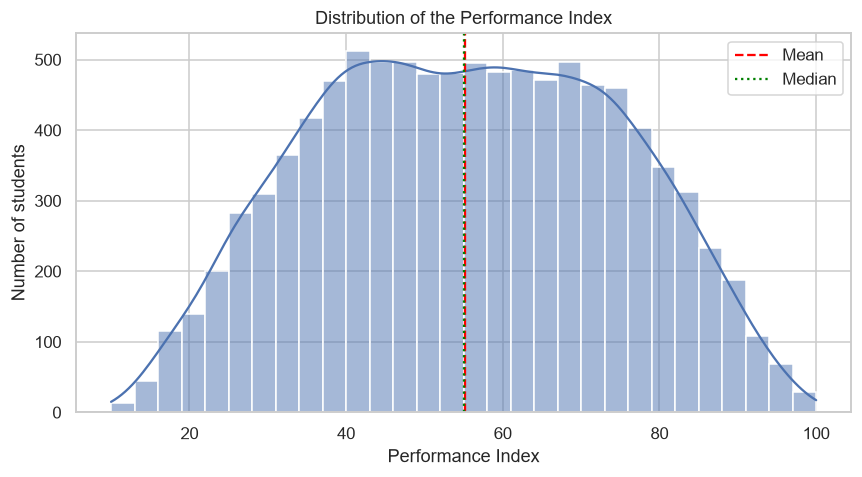

count    9868.00
mean       55.20
std        19.22
min        10.00
25%        40.00
50%        55.00
75%        70.25
max       100.00
Name: Performance Index, dtype: float64


In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(df["Performance Index"], bins=30, kde=True, ax=ax)
ax.axvline(df["Performance Index"].mean(), color="red", linestyle="--", label="Mean")
ax.axvline(df["Performance Index"].median(), color="green", linestyle=":", label="Median")
ax.set_title("Distribution of the Performance Index")
ax.set_xlabel("Performance Index")
ax.set_ylabel("Number of students")
ax.legend()
plt.tight_layout()
plt.show()

print(df["Performance Index"].describe().round(2))

### 4.2 Correlation with the target

The heatmap summarizes linear relationships. `Previous Scores` is by far the strongest signal; `Hours Studied` is a clear second. `Sleep Hours` and `Sample Question Papers Practiced` are weak on their own, but they can still help a model in combination with other features.

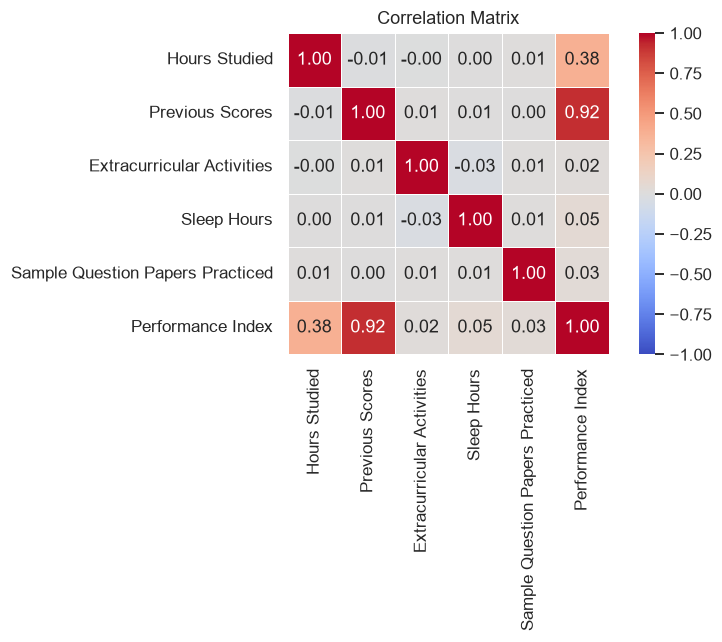

Performance Index                   1.000
Previous Scores                     0.915
Hours Studied                       0.375
Sleep Hours                         0.050
Sample Question Papers Practiced    0.032
Extracurricular Activities          0.022
Name: Performance Index, dtype: float64

In [11]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True,
)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

df.corr(numeric_only=True)["Performance Index"].sort_values(ascending=False).round(3)

### 4.3 Relationships with the target

The scatter plots below show why the models can fit this dataset so well: `Previous Scores` follows an almost linear pattern, and `Hours Studied` adds a smaller but consistent increase.

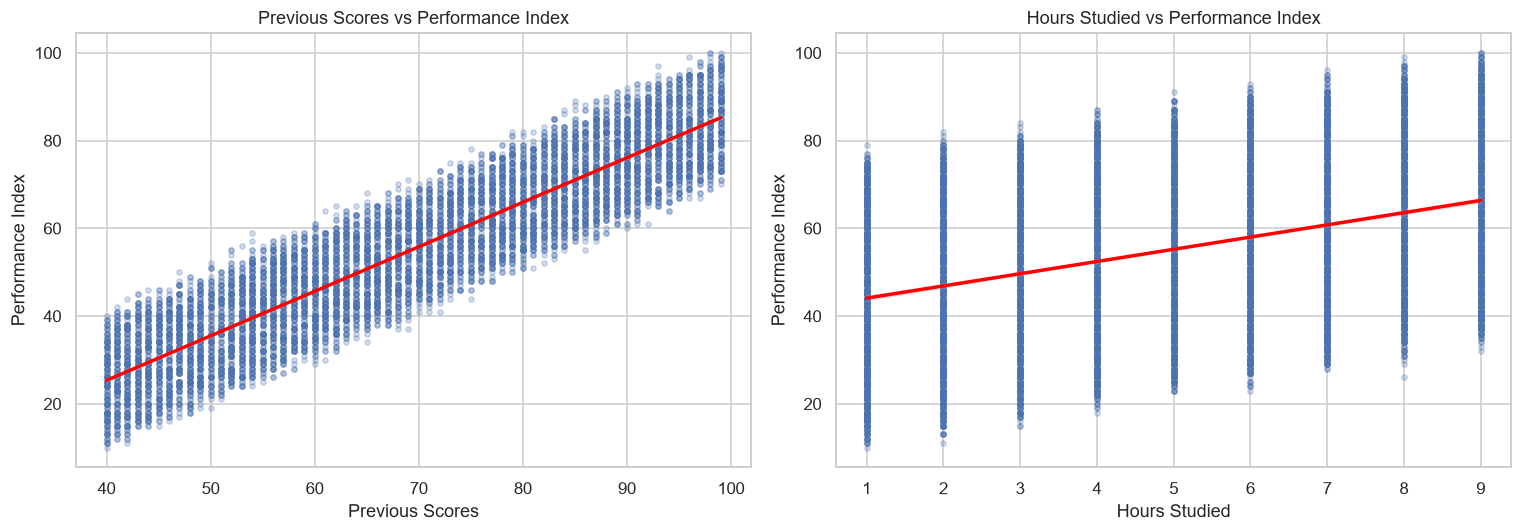

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Previous Scores: the strongest predictor
sns.regplot(
    data=df,
    x="Previous Scores",
    y="Performance Index",
    scatter_kws={"alpha": 0.25, "s": 12},
    line_kws={"color": "red"},
    ax=axes[0],
)
axes[0].set_title("Previous Scores vs Performance Index")

# Hours Studied: a positive but noisier relationship
sns.regplot(
    data=df,
    x="Hours Studied",
    y="Performance Index",
    scatter_kws={"alpha": 0.25, "s": 12},
    line_kws={"color": "red"},
    ax=axes[1],
)
axes[1].set_title("Hours Studied vs Performance Index")

plt.tight_layout()
plt.show()

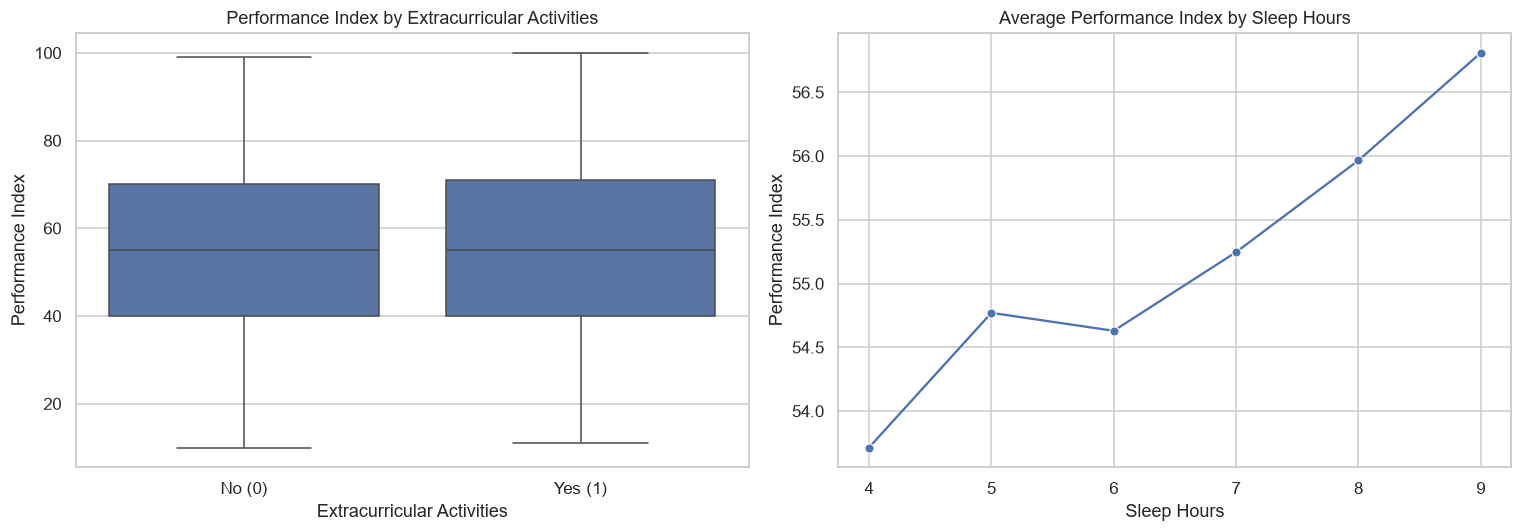

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Extracurricular activities: compare the target distribution for Yes vs No
sns.boxplot(
    data=df,
    x="Extracurricular Activities",
    y="Performance Index",
    ax=axes[0],
)
axes[0].set_xticks([0, 1], ["No (0)", "Yes (1)"])
axes[0].set_title("Performance Index by Extracurricular Activities")

# Sleep hours: average target per sleep value
sleep_means = df.groupby("Sleep Hours")["Performance Index"].mean().reset_index()
sns.lineplot(
    data=sleep_means,
    x="Sleep Hours",
    y="Performance Index",
    marker="o",
    ax=axes[1],
)
axes[1].set_title("Average Performance Index by Sleep Hours")

plt.tight_layout()
plt.show()

**EDA takeaways**

- `Previous Scores` has a correlation of about **0.92** with the target and dominates the prediction.
- `Hours Studied` adds a smaller positive effect (about **0.37**).
- `Sleep Hours` and `Sample Question Papers Practiced` have weak linear correlations (below **0.05**), so they are unlikely to change the ranking of models much.
- Because the main relationship is close to linear, a well-regularized linear model is a strong baseline, while tree ensembles can capture the remaining non-linearity.

## 5. Prepare the data for modeling

### 5.1 Features, target, and train/test split

The data is split **before** any scaling. The model is trained on 80% of the rows and evaluated on the unseen 20%. `random_state=42` makes the split reproducible.

In [14]:
X = df.drop(columns="Performance Index")
y = df["Performance Index"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print(f"Training rows: {len(X_train):,}")
print(f"Test rows:     {len(X_test):,}")
print(f"Features:      {list(X.columns)}")

Training rows: 7,894
Test rows:     1,974
Features:      ['Hours Studied', 'Previous Scores', 'Extracurricular Activities', 'Sleep Hours', 'Sample Question Papers Practiced']


### 5.2 Scaling without data leakage

`MinMaxScaler` maps every feature to the `[0, 1]` range. It is **fit on the training set only** and then applied to the test set. Fitting on the full dataset would let information from the test rows influence training, which is a form of **data leakage** and inflates the reported scores.

Scaling matters for models that use distances or regularisation (KNN, SVR, Ridge, Lasso). Tree-based models do not need it, but applying the same scaled input keeps the comparison fair and the code simple.

In [15]:
scaler = MinMaxScaler()

# Fit on training data only, then transform both sets with the same rules
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Train range after scaling: {X_train_scaled.min():.2f} to {X_train_scaled.max():.2f}")
print(f"Test range after scaling:  {X_test_scaled.min():.2f} to {X_test_scaled.max():.2f}")

Train range after scaling: 0.00 to 1.00
Test range after scaling:  0.00 to 1.00


## 6. Train and compare models

The models below cover four families:

- **Linear models** - Linear Regression, Ridge, Lasso
- **Distance and kernel models** - KNN, SVR
- **Tree-based models** - Decision Tree, Random Forest, ExtraTrees, Bagging
- **Boosting and ensembles** - AdaBoost, GradientBoosting, HistGradientBoosting, XGBoost, LightGBM, CatBoost (when installed), Stacking

All models use the same scaled training data, so the comparison is fair.

In [16]:
models = {
    # Linear models
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.01, max_iter=10_000),

    # Distance / kernel models
    "KNN": KNeighborsRegressor(n_neighbors=5, metric="minkowski", p=1),
    "SVR": SVR(kernel="linear", C=100, epsilon=0.1),

    # Tree-based models
    "Decision Tree": DecisionTreeRegressor(max_depth=10, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, max_depth=None, n_jobs=-1, random_state=RANDOM_STATE
    ),
    "ExtraTrees": ExtraTreesRegressor(
        n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE
    ),
    "Bagging": BaggingRegressor(
        estimator=DecisionTreeRegressor(max_depth=10, random_state=RANDOM_STATE),
        n_estimators=50,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),

    # Boosting models
    "AdaBoost": AdaBoostRegressor(n_estimators=100, random_state=RANDOM_STATE),
    "GradientBoosting": GradientBoostingRegressor(
        n_estimators=200, learning_rate=0.05, random_state=RANDOM_STATE
    ),
    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=200, learning_rate=0.05, random_state=RANDOM_STATE
    ),
    "XGBoost": XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.9,
        colsample_bytree=0.9,
        random_state=RANDOM_STATE,
        verbosity=0,
    ),
    "LightGBM": LGBMRegressor(
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        random_state=RANDOM_STATE,
        verbose=-1,
    ),
}

# Add CatBoost only when the optional library is available.
if CatBoostRegressor is not None:
    models["CatBoost"] = CatBoostRegressor(
        iterations=300, learning_rate=0.05, verbose=0, random_state=RANDOM_STATE
    )
else:
    print("CatBoost is not installed, so it is skipped.")

CatBoost is not installed, so it is skipped.


### 6.1 Evaluation helper

Each model is scored with four standard regression metrics:

| Metric | Meaning | Better when |
| --- | --- | --- |
| MAE | Average absolute error in target points | Lower |
| MSE | Average squared error (penalizes large errors) | Lower |
| RMSE | Square root of MSE (same unit as the target) | Lower |
| R² | Share of the target variance explained | Higher (max 1.0) |

Metrics are computed on both the training and test sets. A large gap between them would indicate overfitting.

In [17]:
def regression_metrics(model, X_data, y_true):
    """Return MAE, MSE, RMSE, and R2 for a fitted model."""
    y_pred = model.predict(X_data)
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2}

### 6.2 Training loop

Every model is fitted once, evaluated on train and test, and stored in `fitted_models` so the best one can be reused later.

In [18]:
results = {}
fitted_models = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)

    train_scores = regression_metrics(model, X_train_scaled, y_train)
    test_scores = regression_metrics(model, X_test_scaled, y_test)

    results[name] = {
        "MAE Train": train_scores["MAE"],
        "MAE Test": test_scores["MAE"],
        "MSE Train": train_scores["MSE"],
        "MSE Test": test_scores["MSE"],
        "RMSE Train": train_scores["RMSE"],
        "RMSE Test": test_scores["RMSE"],
        "R2 Train": train_scores["R2"],
        "R2 Test": test_scores["R2"],
    }
    fitted_models[name] = model

print(f"Trained {len(fitted_models)} models.")

Trained 14 models.


### 6.3 Stacking ensemble

Stacking trains several different models and lets a meta-model combine their predictions. The base models are deliberately varied (forest, gradient boosting, LightGBM, and CatBoost when it is installed), and a small Ridge model acts as the meta-learner.

This step is separate from the loop above because it needs a list of `(name, model)` pairs and its own cross-validation setup.

In [19]:
stacking_base_models = [
    ("rf", RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE)),
    ("gb", GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, random_state=RANDOM_STATE)),
]

# Include CatBoost only when it is installed.
if CatBoostRegressor is not None:
    stacking_base_models.append(
        ("cat", CatBoostRegressor(iterations=100, learning_rate=0.05, verbose=0, random_state=RANDOM_STATE))
    )

stacking_base_models.append(
    ("lgb", LGBMRegressor(n_estimators=100, learning_rate=0.05, random_state=RANDOM_STATE, verbose=-1))
)

stacking_model = StackingRegressor(
    estimators=stacking_base_models,
    final_estimator=Ridge(alpha=1.0),
    cv=5,
    n_jobs=-1,
)

stacking_model.fit(X_train_scaled, y_train)

train_scores = regression_metrics(stacking_model, X_train_scaled, y_train)
test_scores = regression_metrics(stacking_model, X_test_scaled, y_test)

results["Stacking"] = {
    "MAE Train": train_scores["MAE"],
    "MAE Test": test_scores["MAE"],
    "MSE Train": train_scores["MSE"],
    "MSE Test": test_scores["MSE"],
    "RMSE Train": train_scores["RMSE"],
    "RMSE Test": test_scores["RMSE"],
    "R2 Train": train_scores["R2"],
    "R2 Test": test_scores["R2"],
}
fitted_models["Stacking"] = stacking_model

print("Stacking model trained.")

Stacking model trained.


## 7. Results

The table is sorted by **test R²**, the main ranking metric. Because the data is close to linear, the top models are expected to be very close; small differences should not be over-interpreted.

In [20]:
results_df = (
    pd.DataFrame(results)
    .T
    .sort_values("R2 Test", ascending=False)
)

results_df.round(4)

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
SVR,1.6452,1.6534,4.2971,4.3113,2.0729,2.0764,0.9883,0.9886
Linear Regression,1.6453,1.6541,4.2962,4.3137,2.0727,2.0770,0.9883,0.9886
Ridge,1.6454,1.6550,4.2970,4.3182,2.0729,2.0780,0.9883,0.9886
Lasso,1.6460,1.6573,4.3010,4.3239,2.0739,2.0794,0.9883,0.9886
XGBoost,1.5902,1.7075,3.9984,4.5628,1.9996,2.1361,0.9891,0.9879
GradientBoosting,1.6291,1.7071,4.1953,4.5793,2.0482,2.1399,0.9886,0.9879
HistGradientBoosting,1.5321,1.7262,3.7263,4.6715,1.9304,2.1614,0.9898,0.9876
Stacking,1.5818,1.7304,3.9654,4.6845,1.9913,2.1644,0.9892,0.9876
LightGBM,1.4935,1.7340,3.5467,4.7125,1.8833,2.1708,0.9903,0.9875
Bagging,1.3258,1.8280,2.7645,5.2352,1.6627,2.2880,0.9925,0.9862


### 7.1 Test R² and test error

The charts make the ranking easier to read. R² should be close to 1, while MAE and RMSE are measured in **Performance Index points**.

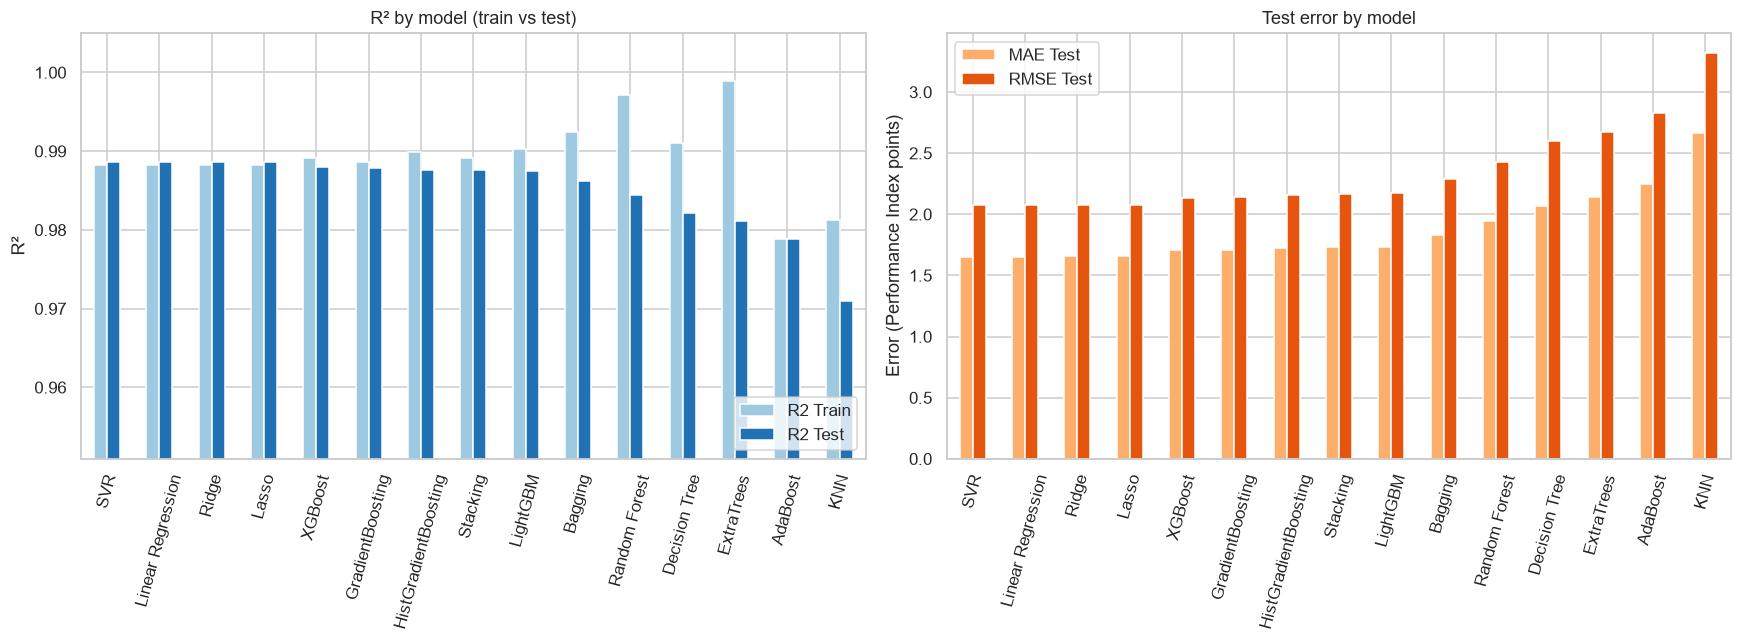

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# R2 comparison: train vs test
results_df[["R2 Train", "R2 Test"]].plot(
    kind="bar", ax=axes[0], color=["#9ecae1", "#2171b5"]
)
axes[0].set_title("R² by model (train vs test)")
axes[0].set_ylabel("R²")
r2_floor = max(0, results_df[["R2 Train", "R2 Test"]].min().min() - 0.02)
axes[0].set_ylim(r2_floor, 1.005)
axes[0].tick_params(axis="x", rotation=75)
axes[0].legend(loc="lower right")

# Test errors
results_df[["MAE Test", "RMSE Test"]].plot(
    kind="bar", ax=axes[1], color=["#fdae6b", "#e6550d"]
)
axes[1].set_title("Test error by model")
axes[1].set_ylabel("Error (Performance Index points)")
axes[1].tick_params(axis="x", rotation=75)
axes[1].legend(loc="upper left")

plt.tight_layout()
plt.show()

### 7.2 Best model

The best model is selected automatically from the comparison table. Its train and test scores are printed side by side so overfitting can be checked at a glance.

In [22]:
best_model_name = results_df.index[0]
best_model = fitted_models[best_model_name]

print("=" * 55)
print(f"Best model: {best_model_name}")
print("=" * 55)
print(f"{'Metric':<8}{'Train':>15}{'Test':>15}")
print("-" * 55)
for metric in ["MAE", "MSE", "RMSE", "R2"]:
    print(
        f"{metric:<8}"
        f"{results_df.loc[best_model_name, metric + ' Train']:>15.4f}"
        f"{results_df.loc[best_model_name, metric + ' Test']:>15.4f}"
    )
print("=" * 55)

Best model: SVR
Metric            Train           Test
-------------------------------------------------------
MAE              1.6452         1.6534
MSE              4.2971         4.3113
RMSE             2.0729         2.0764
R2               0.9883         0.9886


### 7.3 Actual vs predicted values

A good model places points close to the red diagonal. The residual plot on the right should be centered around zero with no obvious pattern; a funnel shape would suggest that errors grow for larger predictions.

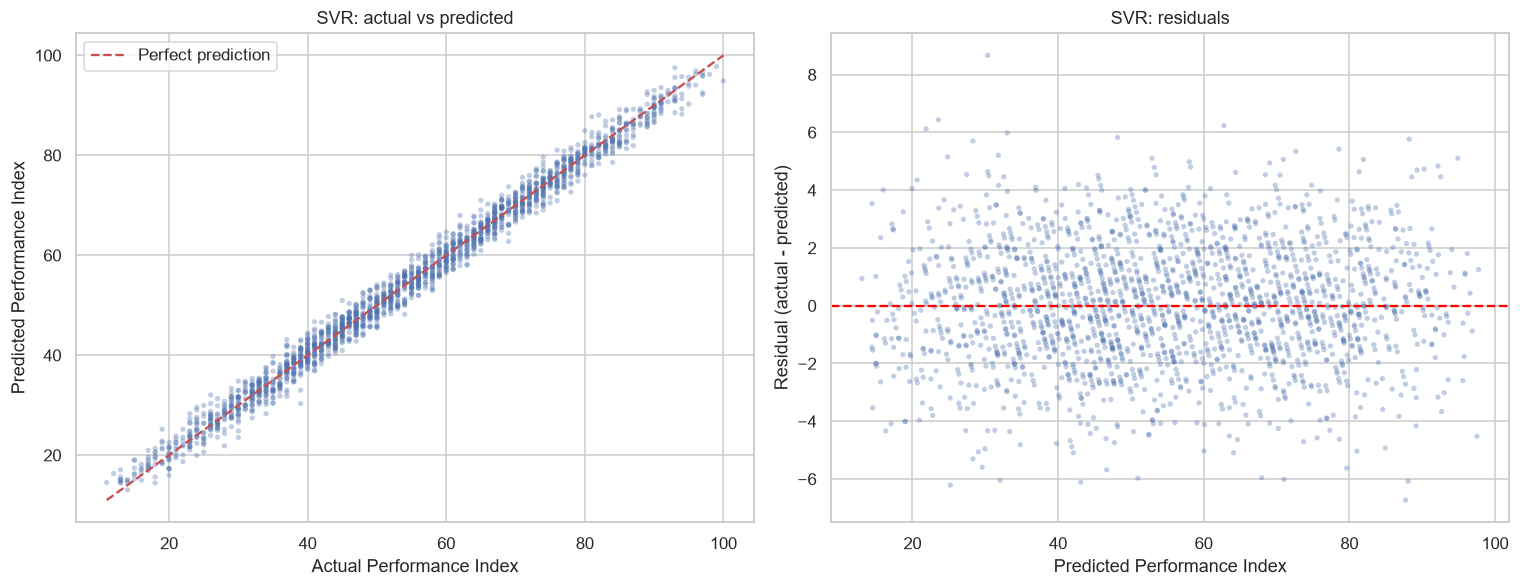

Mean residual: 0.041
Residual standard deviation: 2.076


In [23]:
y_pred = best_model.predict(X_test_scaled)
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Actual vs predicted
axes[0].scatter(y_test, y_pred, alpha=0.35, s=12, edgecolors="none")
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0].plot(lims, lims, "r--", linewidth=1.5, label="Perfect prediction")
axes[0].set_xlabel("Actual Performance Index")
axes[0].set_ylabel("Predicted Performance Index")
axes[0].set_title(f"{best_model_name}: actual vs predicted")
axes[0].legend()

# Residuals
axes[1].scatter(y_pred, residuals, alpha=0.35, s=12, edgecolors="none")
axes[1].axhline(0, color="red", linestyle="--", linewidth=1.5)
axes[1].set_xlabel("Predicted Performance Index")
axes[1].set_ylabel("Residual (actual - predicted)")
axes[1].set_title(f"{best_model_name}: residuals")

plt.tight_layout()
plt.show()

print(f"Mean residual: {residuals.mean():.3f}")
print(f"Residual standard deviation: {residuals.std():.3f}")

### 7.4 What drives the predictions?

If the best model exposes feature importances, they show how much each input contributes to its decisions. Otherwise, the coefficients of a linear model give the direction and size of each effect.

The values below are based on **scaled** features, so they compare relative importance rather than raw units.

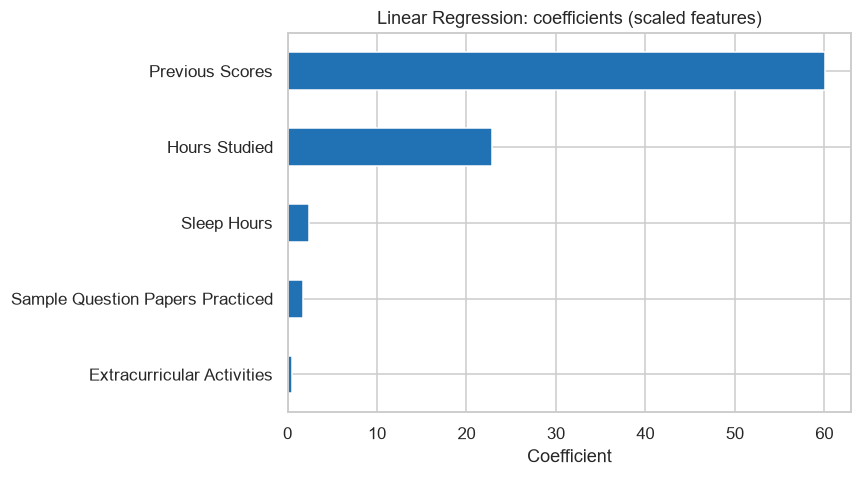

Previous Scores                     60.027
Hours Studied                       22.885
Sleep Hours                          2.400
Sample Question Papers Practiced     1.716
Extracurricular Activities           0.479
dtype: float64

In [24]:
if hasattr(best_model, "feature_importances_"):
    importance = pd.Series(best_model.feature_importances_, index=X.columns)
    importance = importance.sort_values()
    title = f"{best_model_name}: feature importance"
    xlabel = "Importance"
else:
    # Otherwise, use the coefficients of a linear baseline
    linear_model = LinearRegression().fit(X_train_scaled, y_train)
    importance = pd.Series(linear_model.coef_, index=X.columns).sort_values()
    title = "Linear Regression: coefficients (scaled features)"
    xlabel = "Coefficient"

plt.figure(figsize=(8, 4.5))
importance.plot(kind="barh", color="#2171b5")
plt.title(title)
plt.xlabel(xlabel)
plt.tight_layout()
plt.show()

importance.sort_values(ascending=False).round(3)

## 8. Predict a new student

The helper below applies exactly the same preprocessing used during training:

1. Build a one-row DataFrame with the same feature names and order.
2. Encode `Extracurricular Activities` as `1`/`0`.
3. Apply the **already fitted** scaler (never fit it again on new data).
4. Predict and clip the result to the valid `0-100` range.

In [25]:
FEATURES = list(X.columns)


def predict_performance(
    hours_studied,
    previous_scores,
    extracurricular,
    sleep_hours,
    sample_papers,
):
    """Predict a Performance Index for one student.

    Parameters
    ----------
    hours_studied : int or float
        Study hours per day.
    previous_scores : int or float
        Previous exam score (0-100).
    extracurricular : str
        "Yes" or "No".
    sleep_hours : int or float
        Sleep hours per day.
    sample_papers : int or float
        Number of sample question papers practiced.

    Returns
    -------
    float
        Predicted Performance Index, rounded to 2 decimals.
    """
    student = pd.DataFrame(
        [[
            hours_studied,
            previous_scores,
            1 if str(extracurricular).strip().lower() == "yes" else 0,
            sleep_hours,
            sample_papers,
        ]],
        columns=FEATURES,
    )

    student_scaled = scaler.transform(student)
    prediction = float(best_model.predict(student_scaled)[0])

    # The target is defined on a 0-100 scale
    return round(float(np.clip(prediction, 0, 100)), 2)

In [26]:
examples = [
    # hours, previous, extracurricular, sleep, papers
    (7, 99, "Yes", 9, 1),
    (4, 82, "No", 4, 2),
    (5, 60, "Yes", 7, 4),
    (9, 75, "No", 6, 8),
]

for hours, previous, activity, sleep, papers in examples:
    score = predict_performance(hours, previous, activity, sleep, papers)
    print(
        f"Hours={hours}, Previous={previous}, Extracurricular={activity}, "
        f"Sleep={sleep}, Papers={papers}  ->  Predicted score: {score}"
    )

Hours=7, Previous=99, Extracurricular=Yes, Sleep=9, Papers=1  ->  Predicted score: 91.8
Hours=4, Previous=82, Extracurricular=No, Sleep=4, Papers=2  ->  Predicted score: 63.24
Hours=5, Previous=60, Extracurricular=Yes, Sleep=7, Papers=4  ->  Predicted score: 46.03
Hours=9, Previous=75, Extracurricular=No, Sleep=6, Papers=8  ->  Predicted score: 72.49


## 9. interactive Gradio app

The cell below is **disabled by default** so the notebook can run from top to bottom without opening a server or creating a public link.

To try it:

1. Install Gradio: `pip install gradio`
2. Set `RUN_GRADIO = True` in the next cell.
3. Run the cell. Add `share=True` to `demo.launch()` only if you need a temporary public URL.

In [27]:
RUN_GRADIO = False

if RUN_GRADIO:
    import gradio as gr

    demo = gr.Interface(
        fn=predict_performance,
        inputs=[
            gr.Slider(1, 9, step=1, value=5, label="Hours Studied"),
            gr.Slider(40, 99, step=1, value=70, label="Previous Exam Score"),
            gr.Radio(["Yes", "No"], value="No", label="Extracurricular Activities"),
            gr.Slider(4, 9, step=1, value=6, label="Sleep Hours"),
            gr.Slider(0, 9, step=1, value=4, label="Sample Papers Practiced"),
        ],
        outputs=gr.Number(label="Predicted Performance Index"),
        title="Student Performance Predictor",
        description=(
            f"Best model: {best_model_name}. "
            f"Test R²: {results_df.loc[best_model_name, 'R2 Test']:.4f}."
        ),
    )

    # share=True creates a temporary public link; keep it False for local use.
    demo.launch(share=False)
else:
    print("Gradio app is disabled. Set RUN_GRADIO = True to launch it.")

Gradio app is disabled. Set RUN_GRADIO = True to launch it.


## 10. Summary

**What was done**

- Removed 132 duplicate rows and imputed the two columns with missing values.
- Encoded `Extracurricular Activities` as a binary feature.
- Split the data 80/20 and scaled the features using a scaler fitted on the training set only.
- Trained the available regression models (up to 16, depending on optional libraries) and ranked them by test R².

**Key findings**

- `Previous Scores` is the dominant predictor, followed by `Hours Studied`.
- The relationship is close to linear, so SVR, Linear Regression, Ridge, and the tree ensembles all score very high.
- Test scores are consistent with training scores, which means the models generalise well and are not heavily overfitted.

**Possible next steps**

- Tune hyperparameters with `GridSearchCV` or `RandomizedSearchCV`.
- Add cross-validation to report a mean and standard deviation for each model.
- Collect more informative features (for example attendance, assignment completion, or study environment).
- Save the best model and scaler with `joblib` so the prediction function can be reused without retraining.